Using device: cpu
Loading DPT_Large model


Using cache found in /Users/brianbeers/.cache/torch/hub/isl-org_MiDaS_master
Using cache found in /Users/brianbeers/.cache/torch/hub/isl-org_MiDaS_master


Depth predicted in 4.95 seconds
Depth predicted in 5.18 seconds
Creating point cloud
Filtered 18694 outlier points
Point cloud created with 53056 points in 0.43 seconds
Visualization saved to results/resulsts_visualization.png


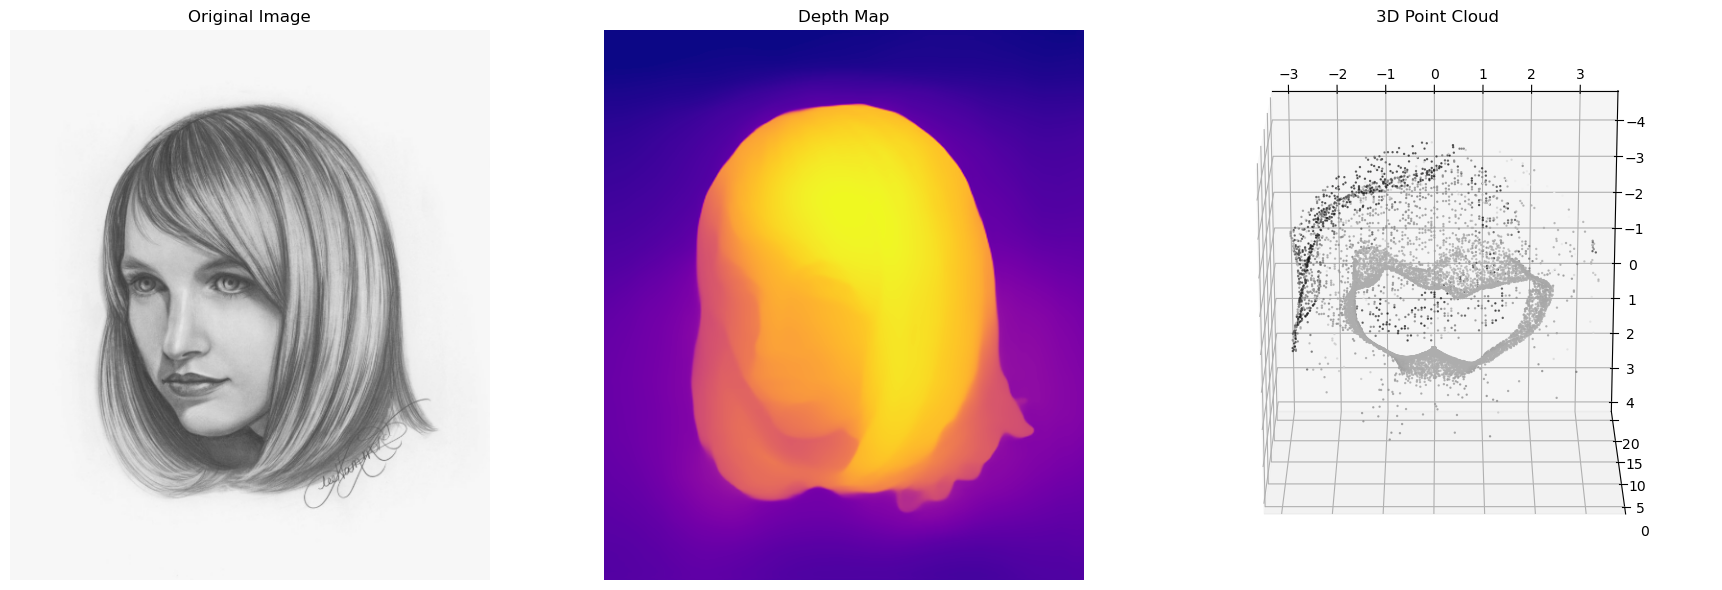

Exporting point cloud to results/point_cloud.ply
Point cloud saved as results/point_cloud.ply
Creating mesh using Delaunay triangulation
Created mesh with 106068 triangles


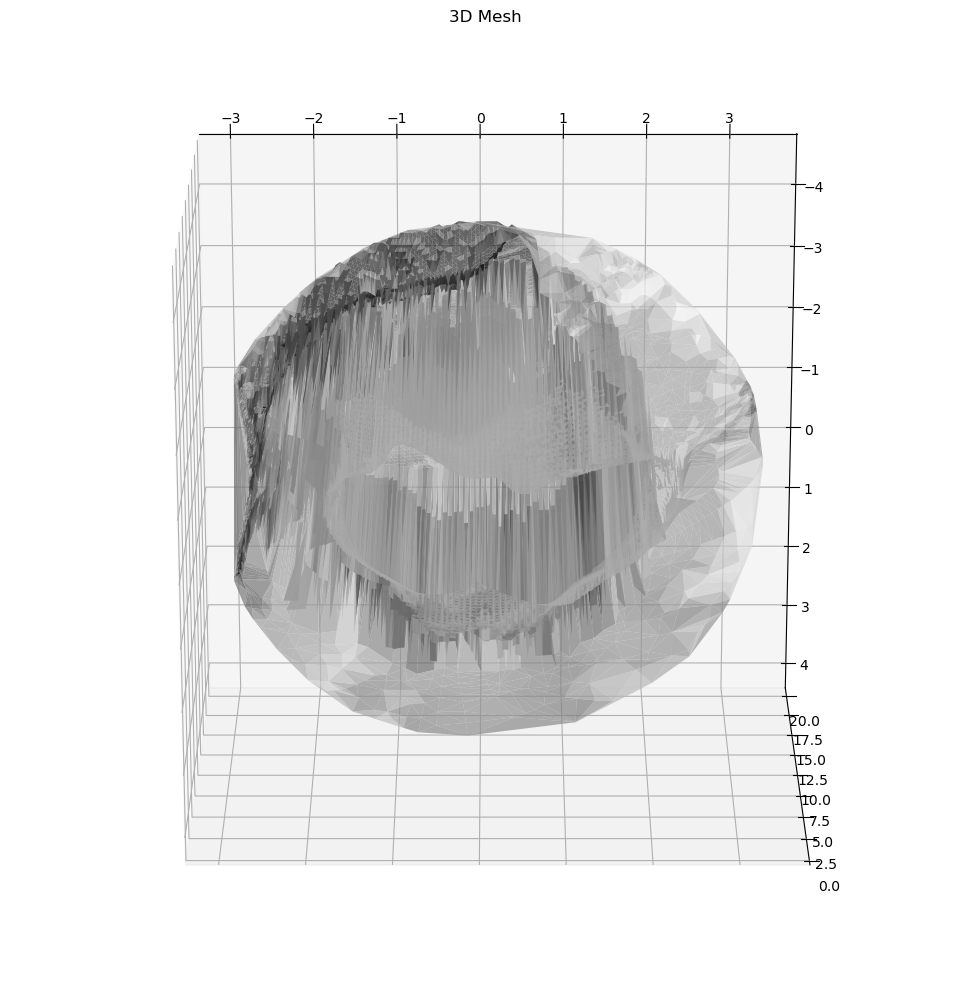

Exporting mesh to results/mesh.obj
Mesh saved as results/mesh.obj
Creating GIF
Animation saved as results/animation.gif
Complete


In [ ]:
import cv2
import torch
import numpy as np
import os
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from PIL import Image
import time
from scipy.spatial import Delaunay
from sklearn.cluster import DBSCAN
from scipy.ndimage import gaussian_filter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 3 different model types "DPT_Large": best quality/slowest, "DPT_Hybrid": medium quality/fast, "MiDaS_small": lower quality/fastest
def loadModel(modelType="DPT_Hybrid"):
    print(f"Loading {modelType} model")
            
    model = torch.hub.load("isl-org/MiDaS", modelType, True)
    midasTransFuncs = torch.hub.load("isl-org/MiDaS", "transforms", trust_repo=True)    
    if modelType == "DPT_Large" or modelType == "DPT_Hybrid":
        transform = midasTransFuncs.dpt_transform
    else:
        transform = midasTransFuncs.small_transform    
    model.to(device)
    model.eval()
    return model, transform

def imgPreprocess(imgPath, contrastEnhance=False, sketchMode=False):
    img = cv2.imread(imgPath)
    if img is None:
        raise FileNotFoundError(f"Could not find or open image at {imgPath}")
    
    og = img.copy()
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    og = cv2.cvtColor(og, cv2.COLOR_BGR2RGB)
    
    if contrastEnhance:
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l)      
        limg = cv2.merge((cl, a, b))
        img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    
    if sketchMode:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        gray = cv2.GaussianBlur(gray, (5, 5), 0)
        edges = cv2.Canny(gray, 50, 150)        
        kernel = np.ones((2, 2), np.uint8)
        edges = cv2.dilate(edges, kernel, iterations=1)        
        edgesRGB = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)        
        img = cv2.addWeighted(img, 0.7, edgesRGB, 0.3, 0)
    
    return img, og

def calcDepth(model, transform, img):
    startTime = time.time()
    inBatch = transform(img).to(device)
    with torch.no_grad():
        prediction = model(inBatch)
        prediction = torch.nn.functional.interpolate(
            prediction.unsqueeze(1),
            size=img.shape[:2],
            mode="bicubic",
            align_corners=False
        ).squeeze()

    depthMap = prediction.cpu().numpy()
    depthNorm = (depthMap - depthMap.min()) / (depthMap.max() - depthMap.min())
    depthColor = cm.plasma(depthNorm)
    
    print(f"Depth predicted in {time.time() - startTime:.2f} seconds")
    return depthMap, depthColor

def calcPtCloud(img, depthMap, dsf=2, filtNoise=True):
    print("Creating point cloud")
    startTime = time.time()
    h, w = depthMap.shape
    fx = fy = max(h, w)  
    cx = w / 2
    cy = h / 2  
    points = []
    colors = []
    
    for i in range(0, h, dsf):
        for k in range(0, w, dsf):
            Z = depthMap[i, k]
            X = (k - cx) * Z / fx
            Y = (i - cy) * Z / fy
            
            points.append([X, -Y, Z]) 
            colors.append(img[i, k] / 255.0)
    
    points = np.array(points)
    colors = np.array(colors)
    if filtNoise and len(points) > 0:
        points, colors = filtOutliers(points, colors)
    
    print(f"Point cloud created with {len(points)} points in {time.time() - startTime:.2f} seconds")
    return points, colors

def filtOutliers(points, colors, stdRatio=2.0):
    if len(points) < 10:  
        return points, colors
    
    try:
        mean = np.mean(points, axis=0)
        std = np.std(points, axis=0)
        dist = np.sqrt(np.sum(((points - mean) / std) ** 2, axis=1))
        mask = dist < stdRatio
        filtPoints = points[mask]
        filtColors = colors[mask]
        print(f"Filtered {len(points) - len(filtPoints)} outlier points")
        return filtPoints, filtColors
    
    except Exception as e:
        print(f"Error in outlier filtering: {e}")
        return points, colors

def clusterPoints(points, colors, eps=0.05, minSamp=10):
    if len(points) < minSamp:
        return points, colors, np.zeros(len(points))
    
    try:
        scaledPoints = (points - points.min(axis=0)) / (points.max(axis=0) - points.min(axis=0))
        db = DBSCAN(eps=eps, minSamp=minSamp).fit(scaledPoints)
        labels = db.labels_
        mask = labels != -1
        filtPoints = points[mask]
        filtColors = colors[mask]
        filtLabels = labels[mask]
        
        print(f"Identified {len(np.unique(filtLabels))} clusters and removed {len(points) - len(filtPoints)} noise points")
        return filtPoints, filtColors, filtLabels
    
    except Exception as e:
        print(f"Error in clustering: {e}")
        return points, colors, np.zeros(len(points))

def improveDepthMap(depthMap, smoothing=1.0):
    depthNoramlized = (depthMap - depthMap.min()) / (depthMap.max() - depthMap.min())
    depthNoramlized = (depthNoramlized * 255).astype(np.uint8)
    filtDepth = cv2.bilateralFilter(depthNoramlized, 9, 75, 75)
    if smoothing > 0:
        filtDepth = gaussian_filter(filtDepth, sigma=smoothing)    
    improvedDepth = filtDepth.astype(np.float32) / 255.0
    improvedDepth = improvedDepth * (depthMap.max() - depthMap.min()) + depthMap.min()
    return improvedDepth

def calcMesh(points, colors):
    print("Creating mesh using Delaunay triangulation")
    if len(points) < 4:
        print("Not enough points for triangulation")
        return None, None, None
    
    try:
        points2D = points[:, :2]
        tri = Delaunay(points2D)        
        faces = tri.simplices        
        faceColors = np.zeros((len(faces), 3))
        for i, face in enumerate(faces):
            faceColors[i] = np.mean(colors[face], axis=0)
        
        print(f"Created mesh with {len(faces)} triangles")
        return points, faces, faceColors
    
    except Exception as e:
        print(f"Error in mesh creation: {e}")
        return None, None, None

def removeBG(img, depthMap, thres=0.8):
    depthNorm = (depthMap - depthMap.min()) / (depthMap.max() - depthMap.min())
    mask = depthNorm < thres    
    imgMasked = img.copy()
    for c in range(3):
        imgMasked[:, :, c] = imgMasked[:, :, c] * mask
    
    return imgMasked

def displayRes(og, depthColor, points, colors, savePath=None):
    fig = plt.figure(figsize=(18, 6))
    ax1 = fig.add_subplot(131)
    ax1.imshow(og)
    ax1.set_title("Original Image")
    ax1.axis('off')
    ax2 = fig.add_subplot(132)
    ax2.imshow(depthColor)
    ax2.set_title("Depth Map")
    ax2.axis('off')
    
    maxPts = 10000
    if len(points) > maxPts:
        idx = np.random.choice(len(points), maxPts, replace=False)
        sampPts = points[idx]
        sampClrs = colors[idx]
    else:
        sampPts = points
        sampClrs = colors
    
    ax3 = fig.add_subplot(133, projection='3d')
    ax3.scatter(
        sampPts[:, 0], 
        sampPts[:, 1], 
        sampPts[:, 2],
        c=sampClrs, 
        s=0.5, 
        alpha=0.7
    )
    ax3.set_title("3D Point Cloud")
    ax3.view_init(elev=-70, azim=-90)
    plt.tight_layout()
    
    if savePath:
        plt.savefig(savePath, dpi=300)
        print(f"Visualization saved to {savePath}")
    
    plt.show()

def displayMesh(verts, faces, faceColors):
    if verts is None or faces is None:
        print("No valid mesh to visualize")
        return
    
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection='3d')
    mesh = ax.plot_trisurf(verts[:, 0], verts[:, 1], verts[:, 2], triangles=faces, alpha=0.7)
    
    try:
        mesh.set_facecolor(faceColors)
    except:
        print("Could not set face colors, using default coloring")
    
    ax.set_title("3D Mesh")
    ax.view_init(elev=-70, azim=-90)
    plt.tight_layout()
    plt.show()

def createGIF(points, colors, outFN="animation.gif"):
    try:
        import imageio
        print("Creating GIF")
        maxPts = 10000
        if len(points) > maxPts:
            idx = np.random.choice(len(points), maxPts, replace=False)
            sampPts = points[idx]
            sampClrs = colors[idx]
        else:
            sampPts = points
            sampClrs = colors
        
        frames = []
        fig = plt.figure(figsize=(8, 8))        
        for angle in range(0, 360, 10):
            ax = fig.add_subplot(111, projection='3d')
            ax.scatter(
                sampPts[:, 0], 
                sampPts[:, 1], 
                sampPts[:, 2],
                c=sampClrs, 
                s=0.5, 
                alpha=0.7
            )
            ax.view_init(elev=30, azim=angle)
            ax.set_axis_off()
            fig.canvas.draw()
            image = np.frombuffer(fig.canvas.tostring_rgb(), dtype='uint8')
            image = image.reshape(fig.canvas.get_width_height()[::-1] + (3,))
            frames.append(image)    
            plt.clf()        
        imageio.mimsave(outFN, frames, fps=10)
        print(f"Animation saved as {outFN}")
        plt.close(fig)
        
    except ImportError:
        print("Imageio not installed")
    except Exception as e:
        print(f"Error creating animation: {e}")

def exportPointCloud(points, colors, outFN="point_cloud.ply"):
    print(f"Exporting point cloud to {outFN}")
    with open(outFN, "w") as f:
        f.write(f"ply\nformat ascii 1.0\nelement vertex {len(points)}\n")
        f.write("property float x\nproperty float y\nproperty float z\n")
        f.write("property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n")
        for p, c in zip(points, colors):
            f.write(f"{p[0]} {p[1]} {p[2]} {int(c[0]*255)} {int(c[1]*255)} {int(c[2]*255)}\n")
    
    print(f"Point cloud saved as {outFN}")

def exportMesh(verts, faces, faceColors, outFN="mesh.obj"):
    if verts is None or faces is None:
        print("No valid mesh to export")
        return
    
    print(f"Exporting mesh to {outFN}")
    with open(outFN, "w") as f:
        for v in verts:
            f.write(f"v {v[0]} {v[1]} {v[2]}\n")
        for face in faces:
            f.write(f"f {face[0]+1} {face[1]+1} {face[2]+1}\n")
    
    mtlFile = outFN.replace(".obj", ".mtl")
    with open(mtlFile, "w") as f:
        for i, color in enumerate(faceColors):
            f.write(f"newmtl material{i}\n")
            f.write(f"Kd {color[0]} {color[1]} {color[2]}\n")
    
    print(f"Mesh saved as {outFN}")

def imgProcess(imgPath, 
                  modelType="DPT_Hybrid", 
                  contrastEnhance=False, 
                  sketchMode=False,
                  removebg=False,
                  bgthres=0.8,
                  smoothDepth=1.0,
                  ds=2,
                  filtNoise=True,
                  createmesh=False,
                  creategif=False,
                  outDir="outputs"):
    
    os.makedirs(outDir, exist_ok=True)
    model, transform = loadModel(modelType)    
    img, og = imgPreprocess(imgPath, contrastEnhance, sketchMode)    
    depthMap, depthColor = calcDepth(model, transform, img)
    
    if smoothDepth > 0:
        depthMap = improveDepthMap(depthMap, smoothDepth)

        depthNorm = (depthMap - depthMap.min()) / (
            depthMap.max() - depthMap.min()
        )
        depthColor = cm.plasma(depthNorm)  
    if removebg:
        img = removeBG(img, depthMap, bgthres)
    
    points, colors = calcPtCloud(img, depthMap, ds, filtNoise)
    visPath = os.path.join(outDir, "resulsts_visualization.png")
    displayRes(og, depthColor, points, colors, visPath)
    plyPath = os.path.join(outDir, "point_cloud.ply")
    exportPointCloud(points, colors, plyPath)
    
    if createmesh and len(points) > 0:
        verts, faces, faceColors = calcMesh(points, colors)
        if verts is not None:
            displayMesh(verts, faces, faceColors)
            objPath = os.path.join(outDir, "mesh.obj")
            exportMesh(verts, faces, faceColors, objPath)
    
    if creategif and len(points) > 0:
        gifPath = os.path.join(outDir, "animation.gif")
        createGIF(points, colors, gifPath)
    
    print("Complete")
    return {
        "depthMap": depthMap,
        "points": points,
        "colors": colors
    }

def main():
    imgPath = ""  # Update this path to your image
    
    imgProcess(
        imgPath=imgPath,
        modelType="DPT_Large",  
        # Options: "DPT_Large", "DPT_Hybrid", "MiDaS_small"
        contrastEnhance=True,     
        # Enhance image contrast
        sketchMode=True,         
        # Set to True for hand-drawn sketches
        removebg=False,           
        # Remove background
        smoothDepth=1.0,          
        # Depth map smoothing factor
        ds=2,              
        # Point cloud downsampling
        filtNoise=True,         
        # Filter noise points
        createmesh=True,          
        # Create and visualize mesh
        creategif=True,    
        # Create animated view
        outDir="results"       
        # Output directory
    )

if __name__ == "__main__":
    main()